# Trust-aware, attack-robust DRL resource allocation: week-2 demonstration

Clean PPO allocator and white-box attacks on it (Phase 1). **All numbers come from our
Python simulator (`rra.env.pysim`), not from ns-3.** The allocator has **no defence yet**
(detector, sanitizer and robust training are Phase 3).

Every table and figure produced here is also written to `results/notebook/`, together with
`manifest.json` (settings, versions, run time), so the outputs can be shown without re-running.

| Section | Content | Time (2 cores, QUICK) |
|---|---|---|
| 0 | Set-up and test suite | ~10 s |
| 1 | Stored week-2 results (3 seeds, 10 episodes per setting) | instant |
| 2 | Live run: PPO vs baselines, clean | ~10 s |
| 3 | Live run: white-box attacks on PPO | ~1.5 min |
| 4 | Optional: short training run | ~4 min per 50 k steps |

## 0. Set-up

In [1]:
import os, sys, json, time, platform, subprocess, pathlib
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

ROOT = pathlib.Path.cwd()
if not (ROOT / "rra").exists():
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

from rra.parallel import available_cores
from experiments.week2_eval import run_many, ci95, METRICS
from rra.env.pysim import PySimEnv
from rra.config import EnvConfig
from rra.baselines import EqualShare, ProportionalFair
from rra.agents.ppo import PPOController
from rra.attacks import Attacker, GradientAttacker, eps_in_physical_units

# ---- settings (QUICK keeps the live sections short; set QUICK = False for the full run) ----
QUICK = True
EPISODES = 4 if QUICK else 10          # evaluation episodes per setting (seeds 1000, 1001, ...)
ATTACK_EPISODES = 3 if QUICK else 6
WORKERS = int(os.environ.get("RRA_WORKERS", available_cores()))
RUN_TRAINING, TRAIN_STEPS = False, 50_000   # section 4
U = 20                                       # mean number of users in the live runs

torch.set_num_threads(1)
OUT = ROOT / "results" / "notebook"; OUT.mkdir(parents=True, exist_ok=True)
T0 = time.time(); MANIFEST = {"simulator": "rra.env.pysim (Python)", "episodes": EPISODES,
                              "attack_episodes": ATTACK_EPISODES, "users": U, "workers": WORKERS}

def save_table(df, name):
    df.to_csv(OUT / f"{name}.csv"); return df

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

print(f"python {platform.python_version()}, torch {torch.__version__}, cores available {available_cores()}, workers {WORKERS}")
env = PySimEnv(EnvConfig(feature_scale="log"))
ckpts = sorted((ROOT / "results/week2").glob("ppo_s*/actor.pt"))
ppos = [PPOController.load(str(p)) for p in ckpts]
print("PPO checkpoints:", [str(p.relative_to(ROOT)) for p in ckpts])

python 3.13.18, torch 2.15.0+cu132, cores available 2, workers 2
PPO checkpoints: ['results/week2/ppo_s0/actor.pt', 'results/week2/ppo_s1/actor.pt', 'results/week2/ppo_s2/actor.pt']


In [2]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "tests"], capture_output=True, text=True)
line = r.stdout.strip().splitlines()[-1]
print(line); MANIFEST["tests"] = line

23 passed in 3.39s


## 1. Stored week-2 results

Trained for 1 M steps on 3 seeds. Clean comparison (E3) and attacks (E4) were evaluated on seeds
1000-1009 (E3) and 1000-1005 (E4), which training never used. 95% intervals are in the CSVs.

controller,U,utility_mean,viol_eMBB_mean,viol_URLLC_mean,viol_mMTC_mean,power_frac_mean,cell_thr_mbps_mean
EqualShare,5,1.051000,0.014000,0.000000,0.000000,1.000000,20.120000
PF,5,1.090000,0.000000,0.049000,0.036000,0.416000,23.380000
NeedPrior,5,1.090000,0.000000,0.161000,0.190000,0.400000,23.350000
PPO,5,1.086000,0.000000,0.000000,0.000000,0.493000,22.970000
EqualShare,10,0.956000,0.139000,0.000000,0.000000,1.000000,28.880000
PF,10,1.039000,0.000000,0.060000,0.034000,0.632000,37.650000
NeedPrior,10,1.040000,0.000000,0.153000,0.176000,0.600000,37.790000
PPO,10,1.037000,0.000000,0.000000,0.000000,0.738000,37.460000
EqualShare,20,0.848000,0.480000,0.006000,0.000000,1.000000,41.670000
PF,20,1.019000,0.090000,0.066000,0.043000,0.982000,69.960000


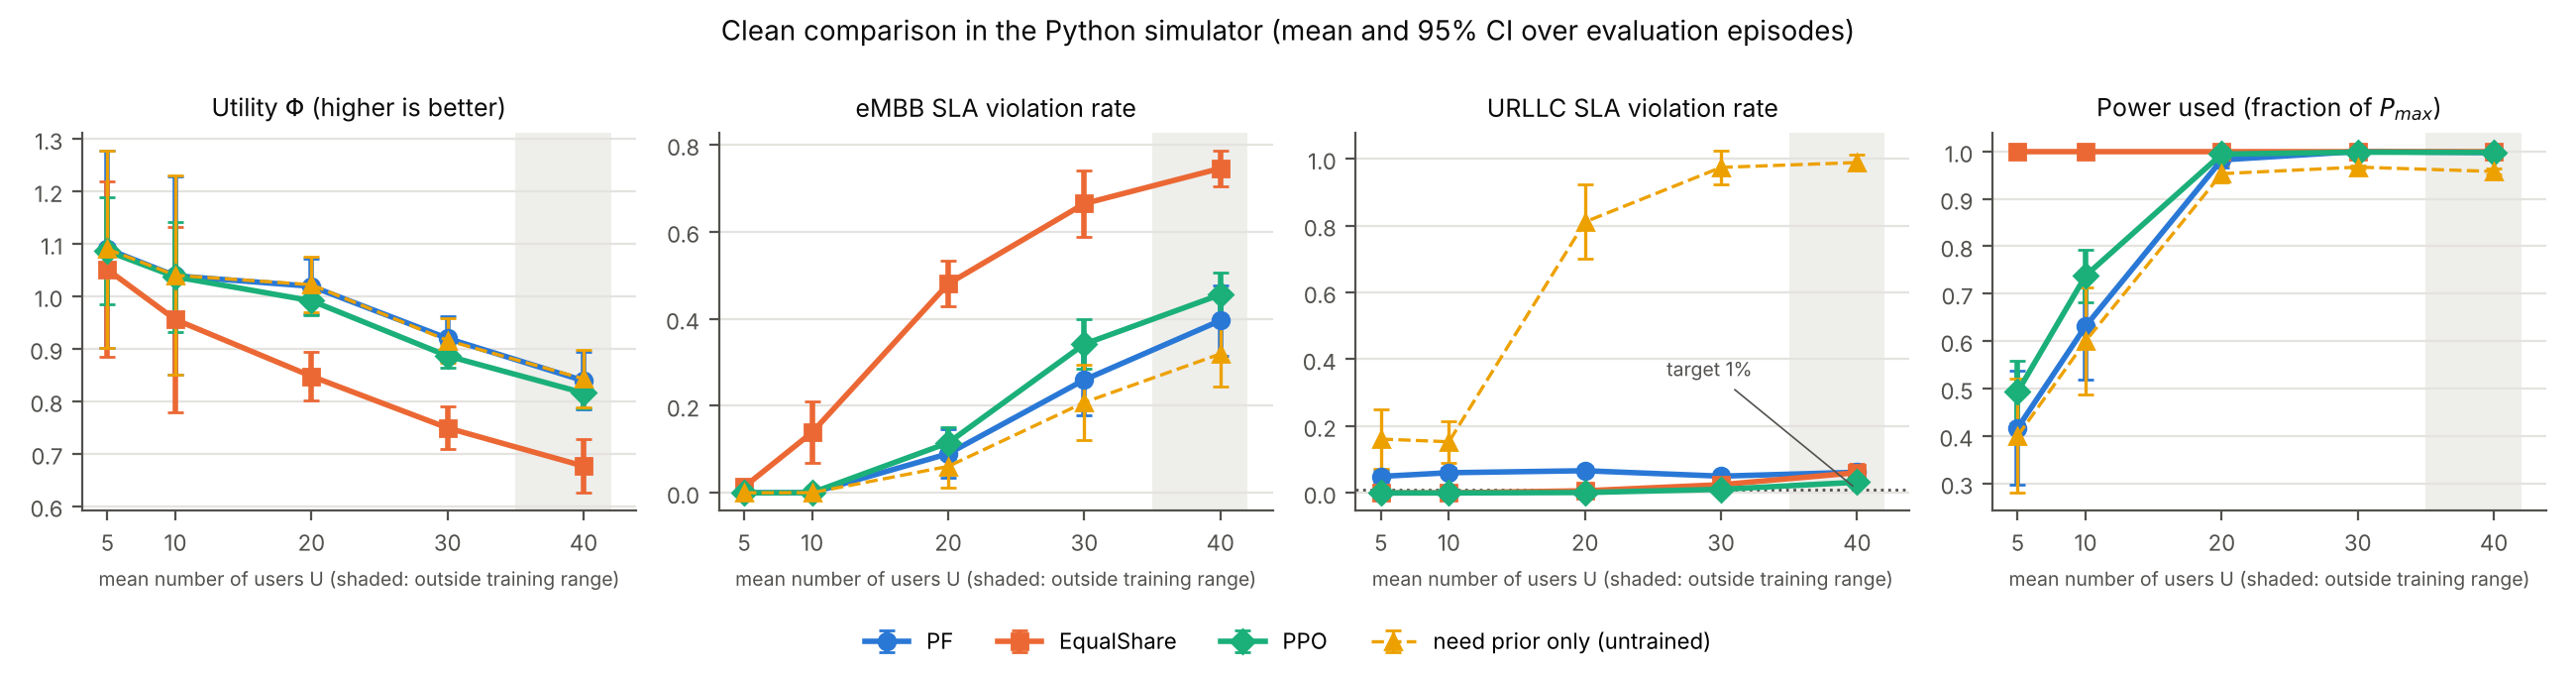

In [3]:
e3 = pd.read_csv("results/week2/e3_clean.csv")
cols = ["controller", "U", "utility_mean", "viol_eMBB_mean", "viol_URLLC_mean", "viol_mMTC_mean",
        "power_frac_mean", "cell_thr_mbps_mean"]
display(e3[cols].round(3).style.hide(axis="index"))
display(Image("results/week2/e3_clean.png"))

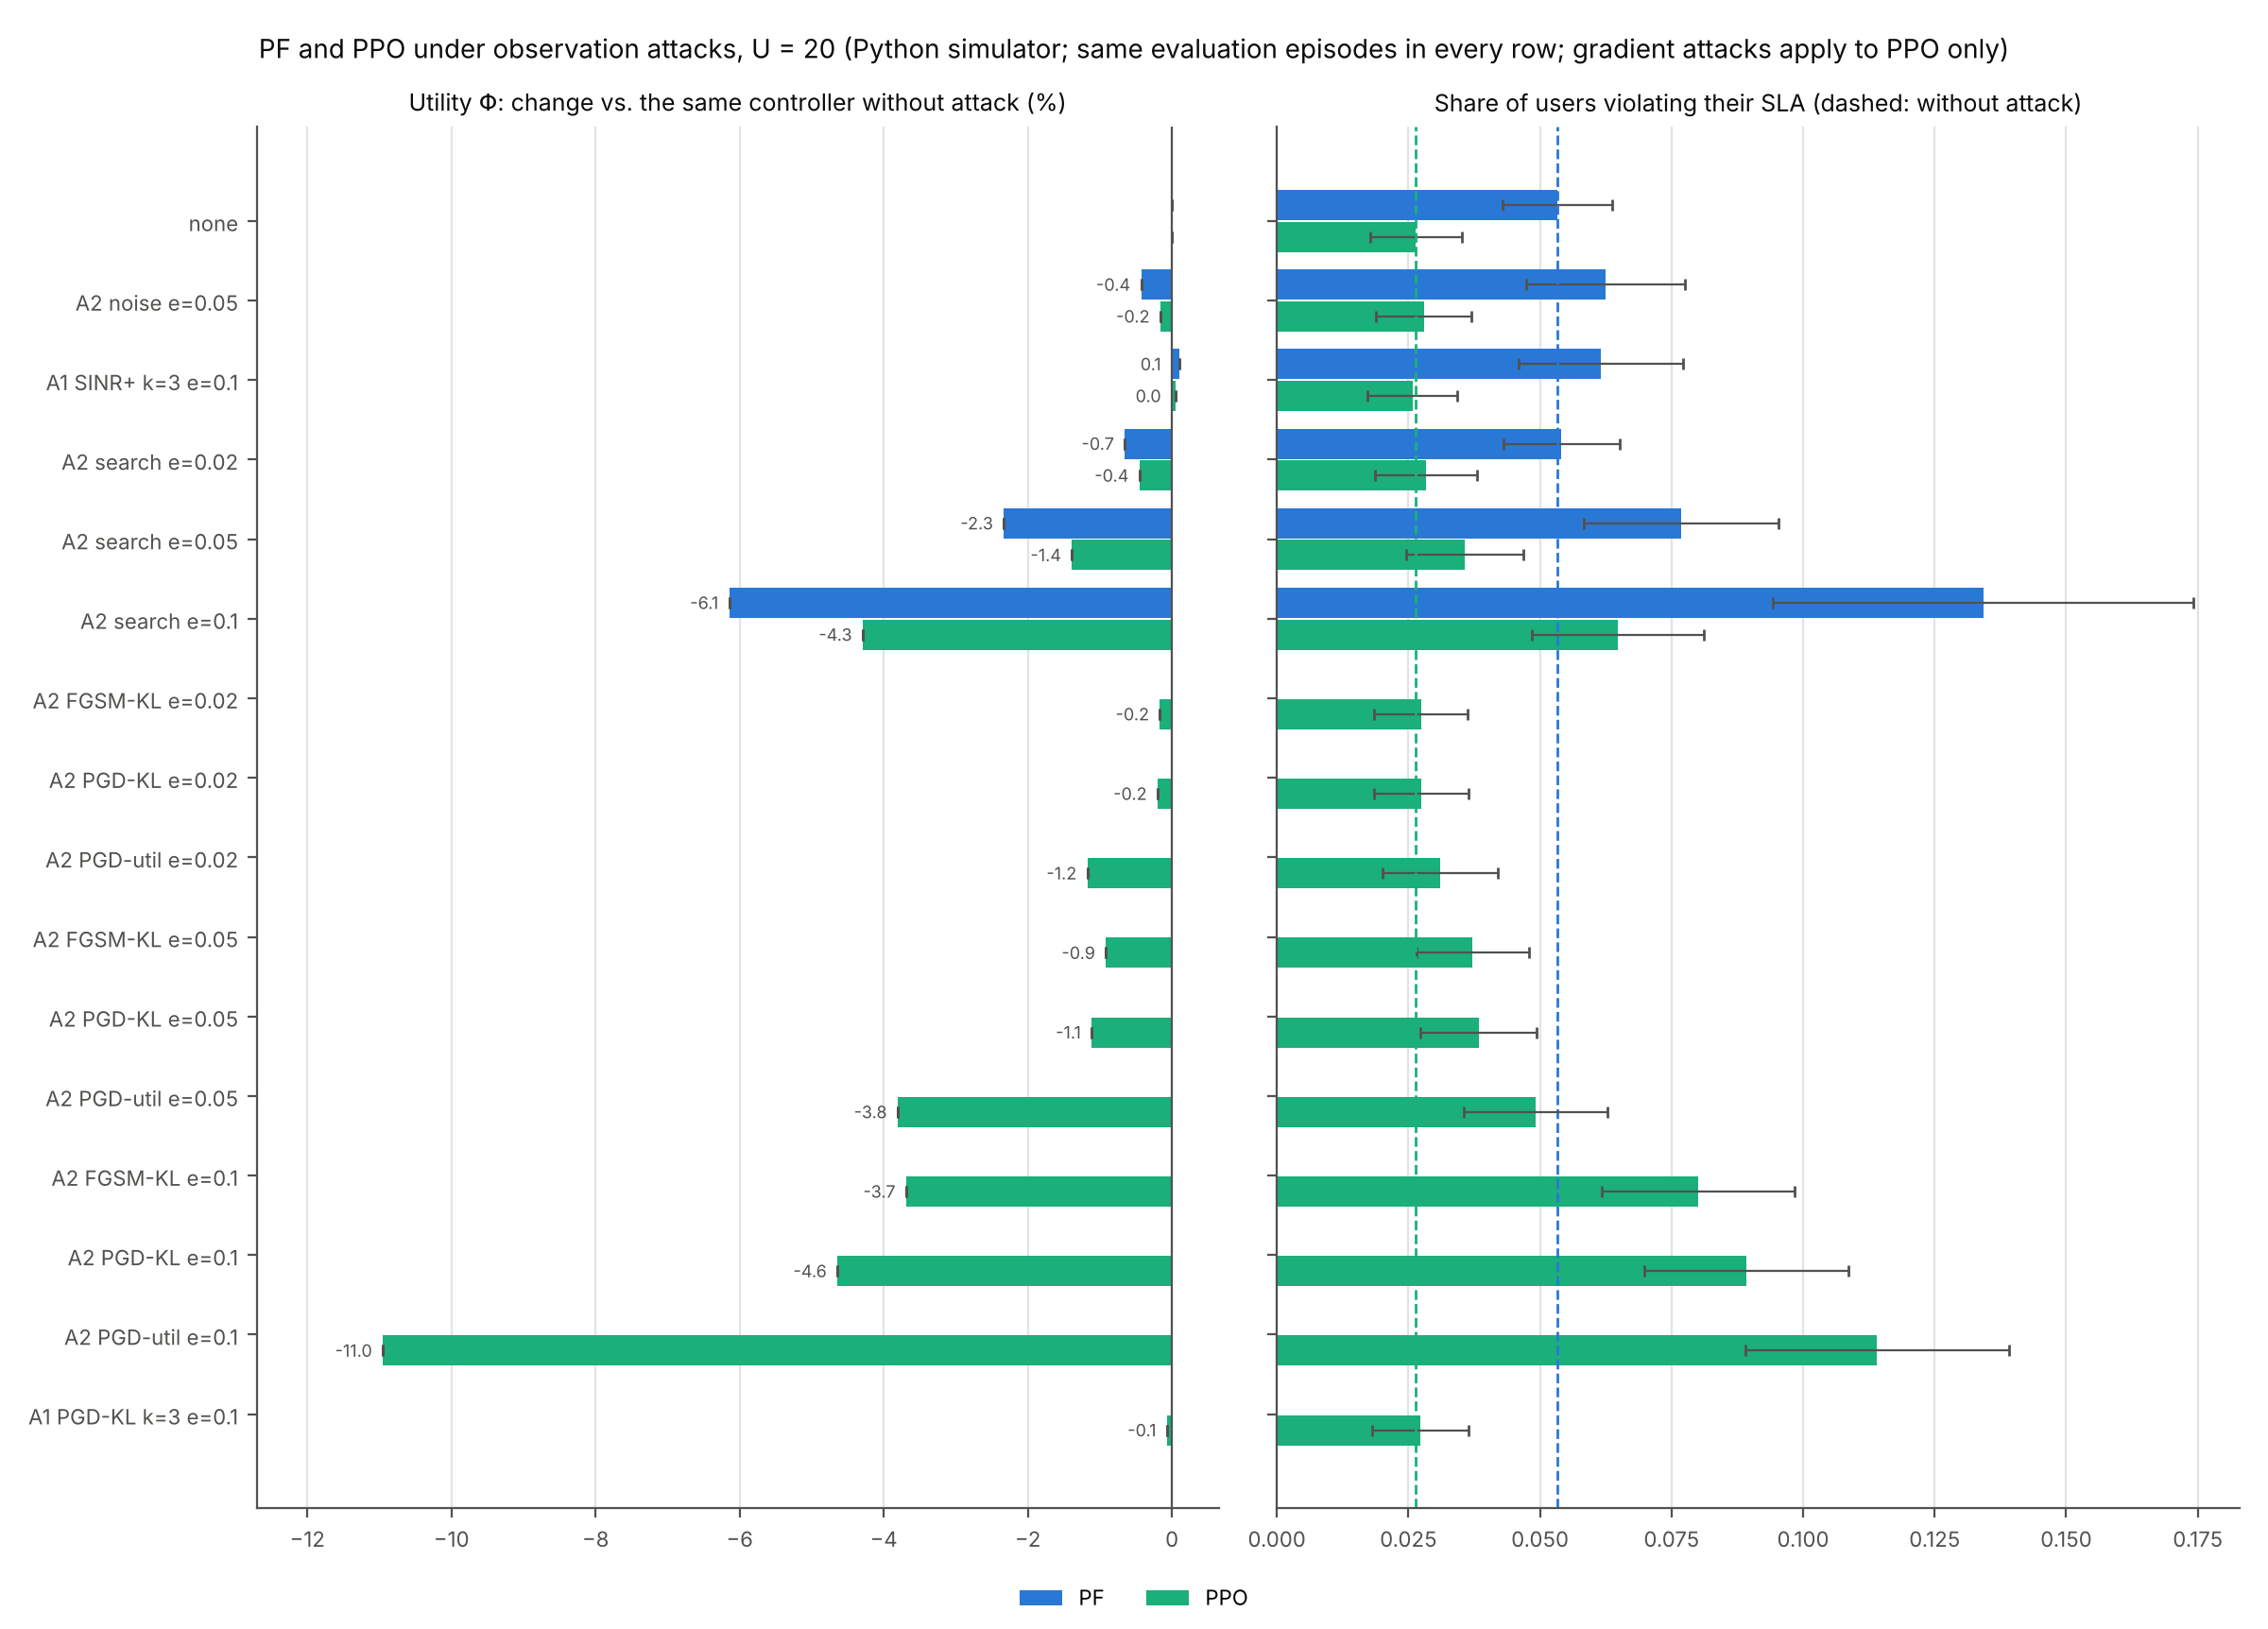

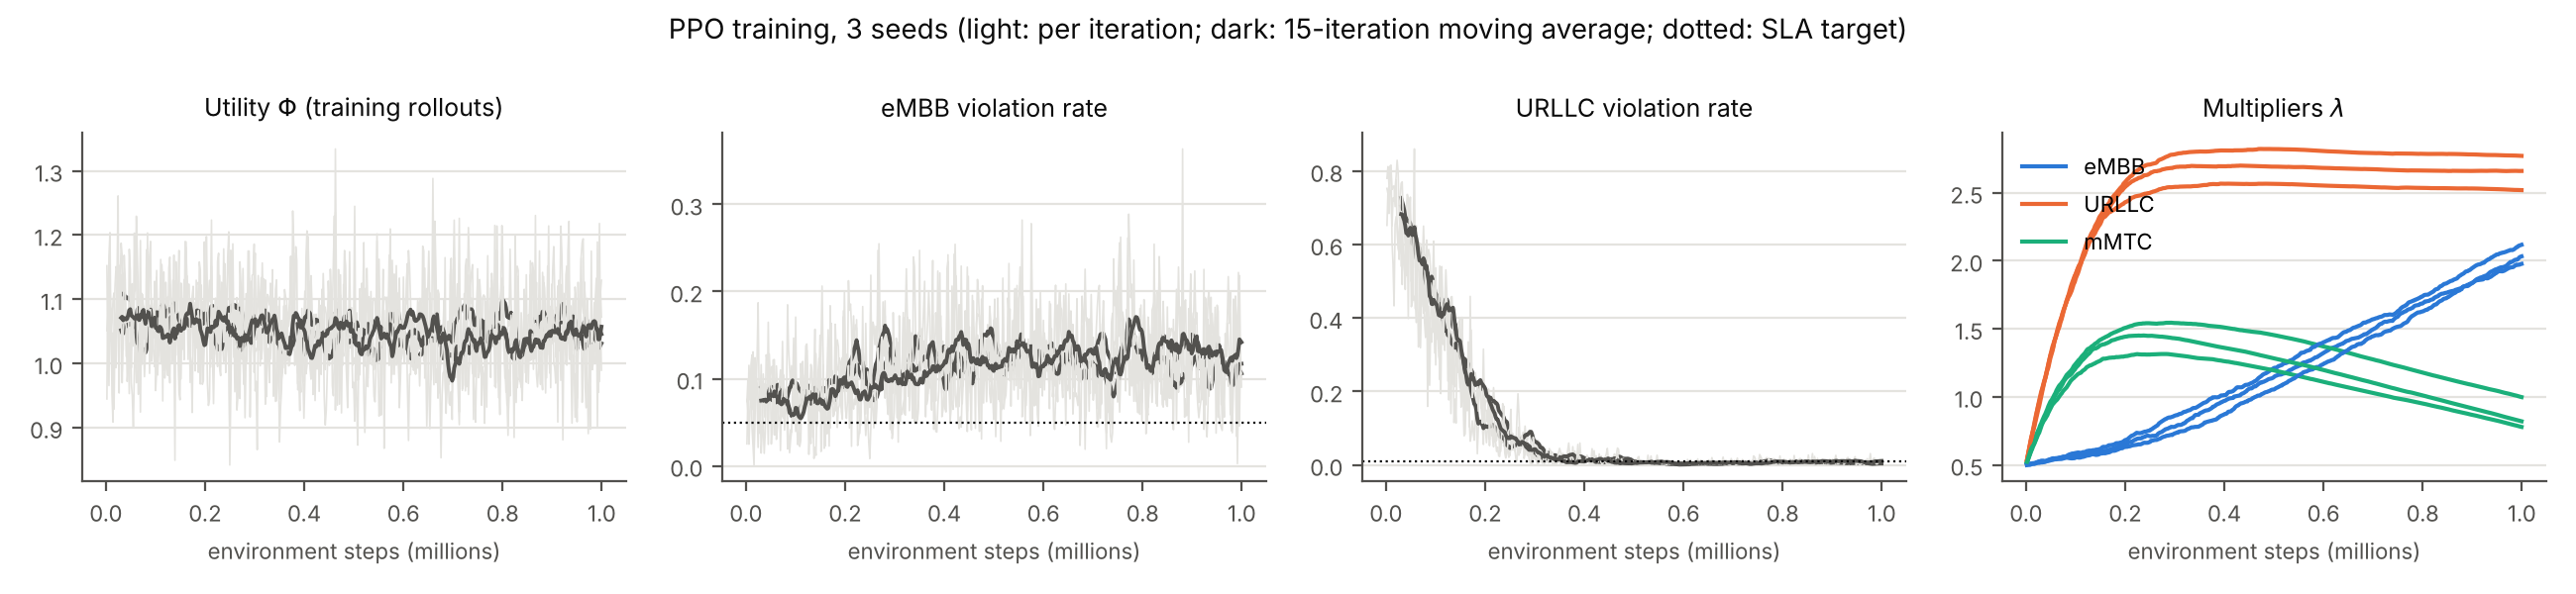

In [4]:
display(Image("results/week2/e4_attacks.png"))
display(Image("results/week2/learning_curves.png"))

## 2. Live run: PPO vs baselines (no attack)

Same simulator, new run. PPO pools all trained seeds. *Violation* is the share of user-intervals
that miss the slice SLA (targets: eMBB 5%, URLLC 1%, mMTC 5%).

In [5]:
t = time.time()
seeds = list(range(1000, 1000 + EPISODES))
rows = {"EqualShare": run_many(env, [EqualShare(env)], None, seeds, U, WORKERS),
        "PF": run_many(env, [ProportionalFair(env)], None, seeds, U, WORKERS),
        "PPO": run_many(env, ppos, None, seeds, U, WORKERS)}
show = ["utility", "viol_eMBB", "viol_URLLC", "viol_mMTC", "power_frac", "cell_thr_mbps", "urllc_p99_delay_ms"]
tab = pd.DataFrame({name: {m: ci95([r[m] for r in rr])[0] for m in show} for name, rr in rows.items()}).T
tab_ci = pd.DataFrame({name: {m: ci95([r[m] for r in rr])[1] for m in show} for name, rr in rows.items()}).T
save_table(tab, "clean_mean"); save_table(tab_ci, "clean_ci95")
display(tab.round(3))
print(f"{len(seeds)} episodes per controller (PPO: {len(seeds) * len(ppos)}), {time.time() - t:.0f} s")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
w = 0.27
for k, (name, col) in enumerate(zip(rows, ["#eb6834", "#2a78d6", "#1baf7a"])):
    ax[0].bar(np.arange(3) + (k - 1) * w, [100 * tab.loc[name, m] for m in ["viol_eMBB", "viol_URLLC", "viol_mMTC"]],
              w, yerr=[100 * tab_ci.loc[name, m] for m in ["viol_eMBB", "viol_URLLC", "viol_mMTC"]], color=col, label=name, capsize=2)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(["eMBB", "URLLC", "mMTC"]); ax[0].set_ylabel("SLA violations (%)")
ax[0].set_title(f"Per-slice violations, U = {U}"); ax[0].legend(frameon=False)
ax[1].bar(list(rows), [tab.loc[n, "utility"] for n in rows], yerr=[tab_ci.loc[n, "utility"] for n in rows],
          color=["#eb6834", "#2a78d6", "#1baf7a"], capsize=3)
ax[1].set_ylim(0.8, 1.1); ax[1].set_ylabel("Utility"); ax[1].set_title("Utility (higher is better)")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
save_fig(fig, "clean_comparison")

,utility,viol_eMBB,viol_URLLC,viol_mMTC,power_frac,cell_thr_mbps,urllc_p99_delay_ms
EqualShare,0.817,0.437,0.007,0.000,1.000,37.573,14.693
PF,0.978,0.037,0.082,0.047,0.973,62.933,45.891
PPO,0.956,0.058,0.001,0.008,0.995,58.055,0.000


4 episodes per controller (PPO: 12), 4 s


## 3. Live run: white-box attacks on PPO (A2, the E2 link)

The attacker changes the reported features of all users within an L-infinity budget ε on the scaled
features: at ε = 0.1 this is ±5 dB on SINR and ×2.6 to ×3.0 on buffer, demand and rate. Each attack
is run on the same episodes as the clean reference, so the change is **paired**; the interval is the
95% interval of the per-episode difference (normal approximation). With `QUICK = True` there are only
3 episodes and one trained model, so the intervals are rough; `QUICK = False` uses 6 episodes and all 3 models.

* `KL`: the report's loss, KL(π(·|s) ‖ π(·|s+δ)).
* `utility`: the attacker's one-step estimate of the utility of the allocation the policy would choose.

In [6]:
display(pd.DataFrame(eps_in_physical_units(env.bounds, 0.1), index=["at eps = 0.1"]).T)

,at eps = 0.1
sinr_db,+/-5 dB
buffer_bits,x2.63 (relative)
demand_bps,x2.69 (relative)
interference_dbm,+/-5 dB
avg_rate_bps,x2.95 (relative)


In [7]:
t = time.time()
aseeds = list(range(1000, 1000 + ATTACK_EPISODES))
model = ppos[:1] if QUICK else ppos             # QUICK: seed-0 model only
base = run_many(env, model, None, aseeds, U, WORKERS)
attacks = {
  "noise 0.05":      lambda: Attacker(eps=0.05, point="A2", strategy="noise"),
  "search 0.1":      lambda: Attacker(eps=0.1, point="A2", strategy="search", n_candidates=16),
  "FGSM-KL 0.1":     lambda: GradientAttacker(eps=0.1, strategy="fgsm", objective="kl"),
  "PGD-KL 0.1":      lambda: GradientAttacker(eps=0.1, strategy="pgd", objective="kl"),
  "PGD-utility 0.05": lambda: GradientAttacker(eps=0.05, strategy="pgd", objective="util"),
  "PGD-utility 0.1": lambda: GradientAttacker(eps=0.1, strategy="pgd", objective="util"),
}
res = {}
for name, fac in attacks.items():
    res[name] = run_many(env, model, fac, aseeds, U, WORKERS)
    print(f"{name:18s} done  ({time.time() - t:.0f} s)", flush=True)

def paired(metric, scale=1.0, rel=False):
    out = {}
    for name, rr in res.items():
        d = np.array([a[metric] - b[metric] for a, b in zip(rr, base)])
        if rel: d = d / np.array([b[metric] for b in base])
        out[name] = ci95(d * scale)
    return out
ut = paired("utility", 100, rel=True)
vi = {n: ci95([100 * (a["any_violation"] - b["any_violation"]) for a, b in zip(rr, base)]) for n, rr in res.items()}
thr = paired("cell_thr_mbps", 100, rel=True)
atab = pd.DataFrame({"utility change (%)": {n: ut[n][0] for n in res}, "± 95%": {n: ut[n][1] for n in res},
                     "throughput change (%)": {n: thr[n][0] for n in res},
                     "users violating, change (pp)": {n: vi[n][0] for n in res}, "± 95% ": {n: vi[n][1] for n in res}})
save_table(atab, "attacks_paired")
print(f"clean utility {np.mean([r['utility'] for r in base]):.3f}, users violating {100*np.mean([r['any_violation'] for r in base]):.1f}%,"
      f" {len(aseeds)} episodes x {len(model)} model(s)")
display(atab.round(2))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
names = list(res); y = np.arange(len(names))
ax.barh(y, [ut[n][0] for n in names], xerr=[ut[n][1] for n in names], color="#eb6834", capsize=3)
ax.set_yticks(y); ax.set_yticklabels(names); ax.invert_yaxis(); ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("utility change vs. no attack (%), paired, 95% interval"); ax.spines[["top", "right"]].set_visible(False)
save_fig(fig, "attacks_utility_change")

noise 0.05         done  (2 s)


search 0.1         done  (16 s)


FGSM-KL 0.1        done  (20 s)


PGD-KL 0.1         done  (38 s)


PGD-utility 0.05   done  (57 s)


PGD-utility 0.1    done  (76 s)


clean utility 0.962, users violating 2.2%, 3 episodes x 1 model(s)


,utility change (%),± 95%,throughput change (%),"users violating, change (pp)",± 95%
noise 0.05,-0.14,0.02,-0.49,0.10,0.12
search 0.1,-3.77,1.60,-12.01,2.59,0.14
FGSM-KL 0.1,-3.43,1.04,-10.69,5.40,1.81
PGD-KL 0.1,-4.33,1.29,-13.42,6.19,1.85
PGD-utility 0.05,-3.82,1.46,-12.24,1.14,0.22
PGD-utility 0.1,-11.08,3.30,-32.81,8.19,4.05


## 4. Optional: short training run

Set `RUN_TRAINING = True` in section 0. This trains one seed for `TRAIN_STEPS` steps (the reported models use
1 M steps, about 75 min per seed on one core). Its output goes to `results/notebook/ppo_demo/` and does not
overwrite the stored models. For several seeds in parallel use `python -m experiments.train_seeds`.

In [8]:
if RUN_TRAINING:
    from rra.agents.ppo import PPOConfig, train
    t = time.time()
    train(PPOConfig(total_steps=TRAIN_STEPS, seed=0), str(OUT / "ppo_demo"), EnvConfig(feature_scale="log"), log_every=5)
    log = pd.read_csv(OUT / "ppo_demo" / "train_log.csv")
    fig, ax = plt.subplots(1, 3, figsize=(11, 3))
    ax[0].plot(log["steps"], log["utility"]); ax[0].set_title("training utility")
    for c in ["viol_eMBB", "viol_URLLC", "viol_mMTC"]:
        ax[1].plot(log["steps"], log[c], label=c)
    ax[1].legend(frameon=False); ax[1].set_title("violation rates")
    for c in ["lambda_eMBB", "lambda_URLLC", "lambda_mMTC"]:
        ax[2].plot(log["steps"], log[c], label=c)
    ax[2].legend(frameon=False); ax[2].set_title("Lagrange multipliers")
    save_fig(fig, "training_demo"); print(f"trained in {time.time() - t:.0f} s")
else:
    print("skipped (RUN_TRAINING = False)")

skipped (RUN_TRAINING = False)


## Run record

In [9]:
MANIFEST.update({"runtime_s": round(time.time() - T0, 1), "python": platform.python_version(),
                 "torch": torch.__version__, "numpy": np.__version__, "cores_available": available_cores(),
                 "ppo_checkpoints": [str(p.relative_to(ROOT)) for p in ckpts],
                 "created": time.strftime("%Y-%m-%d %H:%M:%S")})
json.dump(MANIFEST, open(OUT / "manifest.json", "w"), indent=2)
print(json.dumps(MANIFEST, indent=2))

{
  "simulator": "rra.env.pysim (Python)",
  "episodes": 4,
  "attack_episodes": 3,
  "users": 20,
  "workers": 2,
  "tests": "23 passed in 3.39s",
  "runtime_s": 85.4,
  "python": "3.13.18",
  "torch": "2.15.0+cu132",
  "numpy": "2.5.3",
  "cores_available": 2,
  "ppo_checkpoints": [
    "results/week2/ppo_s0/actor.pt",
    "results/week2/ppo_s1/actor.pt",
    "results/week2/ppo_s2/actor.pt"
  ],
  "created": "2026-11-01 22:51:25"
}
